## Podcast Video-First
## Discovery Feed A/B Test

### Internmo Data Analytics Project

Objective- Training case study modeled on a Spotify-style product experiment. Data cleaning, analyzing and visualing the given dataset.

## Secondary Metric Analysis

In [4]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

In [5]:
# importing dataframe for analysis
df1 = pd.read_csv(r'C:\Spotify_A-B_Test_project\01_Data\02_processed_data\cleaned_activity.csv')
df2 = pd.read_csv(r'C:\Spotify_A-B_Test_project\01_Data\02_processed_data\cleaned_users.csv')

print("Both CSVs imported successfully!")

Both CSVs imported successfully!


### Create a user-level secondary metrics dataset

In [6]:
secondary_summary = (
    df1
    .groupby('User_ID')
    .agg(
        Total_Discovery_Clicks=('Discovery_Feed_Clicks', 'sum'),
        Total_Music_Minutes=('Music_Minutes_Listened', 'sum'),
        Total_App_Crashes=('App_Crashes', 'sum'),
        Recorded_Activity_Days=('Date', 'nunique')
    )
    .reset_index()
)

# Merge secondary metrics with the randomized user list
secondary_analysis = df2.merge(
    secondary_summary,
    on='User_ID',
    how='left'
)

# Check the result
print("Total users:", secondary_analysis['User_ID'].nunique())
print(secondary_analysis.head())

Total users: 2000
   User_ID    Variant         Region Premium_Status  Account_Age_Days  \
0  U428241  Treatment          latam           Free             236.0   
1  U454990    Control         europe           Free             770.0   
2  U195228  Treatment           apac        Premium             983.0   
3  U651302  Treatment  north america           Free             314.0   
4  U926541    Control         europe           Free             430.0   

   Total_Discovery_Clicks  Total_Music_Minutes  Total_App_Crashes  \
0                      16                923.2                  0   
1                       5                406.8                  0   
2                      35                559.5                  0   
3                      13                771.0                  1   
4                      13                377.8                  0   

   Recorded_Activity_Days  
0                      12  
1                       8  
2                      13  
3               

In [7]:
secondary_results = (
    secondary_analysis
    .groupby('Variant')
    .agg(
        Users=('User_ID', 'count'),

        Avg_Discovery_Clicks=(
            'Total_Discovery_Clicks', 'mean'
        ),

        Median_Discovery_Clicks=(
            'Total_Discovery_Clicks', 'median'
        ),

        Avg_Music_Minutes=(
            'Total_Music_Minutes', 'mean'
        ),

        Median_Music_Minutes=(
            'Total_Music_Minutes', 'median'
        ),

        Avg_App_Crashes=(
            'Total_App_Crashes', 'mean'
        ),

        Users_With_Crashes=(
            'Total_App_Crashes',
            lambda x: (x > 0).sum()
        ),

        Avg_Recorded_Days=(
            'Recorded_Activity_Days', 'mean'
        )
    )
)

print(secondary_results.round(2))

           Users  Avg_Discovery_Clicks  Median_Discovery_Clicks  \
Variant                                                           
Control     1015                  9.64                      8.0   
Treatment    985                 13.81                     11.0   

           Avg_Music_Minutes  Median_Music_Minutes  Avg_App_Crashes  \
Variant                                                               
Control               540.18                 516.9             0.23   
Treatment             538.80                 516.2             0.27   

           Users_With_Crashes  Avg_Recorded_Days  
Variant                                           
Control                   197               9.74  
Treatment                 229               9.91  


In [8]:
# Calculate average daily metrics per recorded activity day

secondary_analysis['Daily_Discovery_Clicks'] = (
    secondary_analysis['Total_Discovery_Clicks']
    / secondary_analysis['Recorded_Activity_Days']
)

secondary_analysis['Daily_Music_Minutes'] = (
    secondary_analysis['Total_Music_Minutes']
    / secondary_analysis['Recorded_Activity_Days']
)

secondary_analysis['Daily_App_Crashes'] = (
    secondary_analysis['Total_App_Crashes']
    / secondary_analysis['Recorded_Activity_Days']
)

# Compare daily averages between experiment groups

daily_summary = (
    secondary_analysis
    .groupby('Variant')
    .agg(
        Avg_Daily_Clicks=('Daily_Discovery_Clicks', 'mean'),
        Avg_Daily_Music=('Daily_Music_Minutes', 'mean'),
        Avg_Daily_Crashes=('Daily_App_Crashes', 'mean')
    )
)

print(daily_summary.round(3))

           Avg_Daily_Clicks  Avg_Daily_Music  Avg_Daily_Crashes
Variant                                                        
Control               0.979           55.361              0.024
Treatment             1.401           54.512              0.027


In [9]:
from scipy import stats
import numpy as np

metrics = [
    'Daily_Discovery_Clicks',
    'Daily_Music_Minutes',
    'Daily_App_Crashes'
]

for metric in metrics:

    control = secondary_analysis.loc[
        secondary_analysis['Variant'] == 'Control', metric
    ].dropna()

    treatment = secondary_analysis.loc[
        secondary_analysis['Variant'] == 'Treatment', metric
    ].dropna()

    t_stat, p_value = stats.ttest_ind(
        treatment,
        control,
        equal_var=False
    )

    difference = treatment.mean() - control.mean()

    print(f"\nMetric: {metric}")
    print(f"Control Mean: {control.mean():.4f}")
    print(f"Treatment Mean: {treatment.mean():.4f}")
    print(f"Difference: {difference:.4f}")
    print(f"T-statistic: {t_stat:.4f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: Statistically significant")
    else:
        print("Result: Not statistically significant")


Metric: Daily_Discovery_Clicks
Control Mean: 0.9795
Treatment Mean: 1.4012
Difference: 0.4218
T-statistic: 10.0091
P-value: 0.000000
Result: Statistically significant

Metric: Daily_Music_Minutes
Control Mean: 55.3607
Treatment Mean: 54.5118
Difference: -0.8489
T-statistic: -0.9985
P-value: 0.318161
Result: Not statistically significant

Metric: Daily_App_Crashes
Control Mean: 0.0235
Treatment Mean: 0.0273
Difference: 0.0038
T-statistic: 1.5317
P-value: 0.125751
Result: Not statistically significant


### Secondary Metric Analysis

The experiment showed a statistically significant increase in daily discovery clicks for the Treatment group compared with Control.

- Discovery clicks increased from 0.9795 to 1.4012 per recorded activity day, representing approximately a 43.1% increase (p < 0.001).
- Average daily music listening was slightly lower in Treatment (54.51 vs. 55.36 minutes), but the difference was not statistically significant (p = 0.318).
- Average daily app crashes were slightly higher in Treatment (0.0273 vs. 0.0235), but the difference was not statistically significant (p = 0.126).

The discovery-click result remains statistically significant after Bonferroni correction for three secondary comparisons.

These findings are based on recorded activity days. Incomplete activity coverage and unresolved missing-data semantics limit their interpretation as full-period causal effects.

## Guardrail Analysis

In [10]:
from scipy.stats import chi2_contingency

# Identify users with at least one crash
secondary_analysis['Had_Crash'] = (
    secondary_analysis['Total_App_Crashes'] > 0
)

# Create contingency table
crash_table = pd.crosstab(
    secondary_analysis['Variant'],
    secondary_analysis['Had_Crash']
)

print("Crash incidence table:")
print(crash_table)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(crash_table)

print("\nChi-square statistic:", chi2)
print("P-value:", p_value)

# Calculate crash percentages
crash_percentages = (
    secondary_analysis.groupby('Variant')['Had_Crash'].mean() * 100
)

print("\nPercentage of users with at least one crash:")
print(crash_percentages.round(2))

Crash incidence table:
Had_Crash  False  True 
Variant                
Control      818    197
Treatment    756    229

Chi-square statistic: 4.170847646058281
P-value: 0.04112521997761629

Percentage of users with at least one crash:
Variant
Control      19.41
Treatment    23.25
Name: Had_Crash, dtype: float64


### App Crash Incidence Analysis

The proportion of users experiencing at least one recorded app crash was higher in the Treatment group than in Control.

- Control: 19.41% (197 of 1,015 users)
- Treatment: 23.25% (229 of 985 users)
- Absolute difference: +3.84 percentage points
- Relative increase: approximately 19.8%
- Chi-square statistic: 4.171
- P-value: 0.0411

The difference is statistically significant at the unadjusted 5% level but does not remain significant after Bonferroni correction across four secondary comparisons (adjusted threshold = 0.0125).

This finding warrants investigation before launch. Incomplete activity logging may also affect the measurement of crash incidence.

In [11]:
results_summary = pd.DataFrame([
    {
        'Metric': 'Daily Podcast Listening',
        'Control': 10.3483,
        'Treatment': 11.4238,
        'Difference': 1.0755,
        'P_Value': 0.0149,
        'Result': 'Preliminary positive',
        'Interpretation': 'Treatment higher; missing-data limitations'
    },
    {
        'Metric': 'Daily Discovery Clicks',
        'Control': 0.9795,
        'Treatment': 1.4012,
        'Difference': 0.4218,
        'P_Value': 0.0000001,
        'Result': 'Significant positive',
        'Interpretation': 'Higher discovery engagement'
    },
    {
        'Metric': 'Daily Music Minutes',
        'Control': 55.3607,
        'Treatment': 54.5118,
        'Difference': -0.8489,
        'P_Value': 0.3182,
        'Result': 'Not significant',
        'Interpretation': 'No clear change in music listening'
    },
    {
        'Metric': 'Daily App Crashes',
        'Control': 0.0235,
        'Treatment': 0.0273,
        'Difference': 0.0038,
        'P_Value': 0.1258,
        'Result': 'Not significant',
        'Interpretation': 'No significant difference in crash rate'
    },
    {
        'Metric': 'Users with at least one crash (%)',
        'Control': 19.41,
        'Treatment': 23.25,
        'Difference': 3.84,
        'P_Value': 0.0411,
        'Result': 'Nominally significant',
        'Interpretation': 'Higher crash incidence in Treatment'
    }
])

print(results_summary.to_string(index=False))

                           Metric  Control  Treatment  Difference      P_Value                Result                             Interpretation
          Daily Podcast Listening  10.3483    11.4238      1.0755 1.490000e-02  Preliminary positive Treatment higher; missing-data limitations
           Daily Discovery Clicks   0.9795     1.4012      0.4218 1.000000e-07  Significant positive                Higher discovery engagement
              Daily Music Minutes  55.3607    54.5118     -0.8489 3.182000e-01       Not significant         No clear change in music listening
                Daily App Crashes   0.0235     0.0273      0.0038 1.258000e-01       Not significant    No significant difference in crash rate
Users with at least one crash (%)  19.4100    23.2500      3.8400 4.110000e-02 Nominally significant        Higher crash incidence in Treatment


In [12]:
results_summary.to_csv(
   r'C:\Spotify_A-B_Test_project\01_Data\02_processed_data\experiment_results_summary.csv',
    index=False
)

print("Results summary saved successfully.")

Results summary saved successfully.


## Final Visualisations

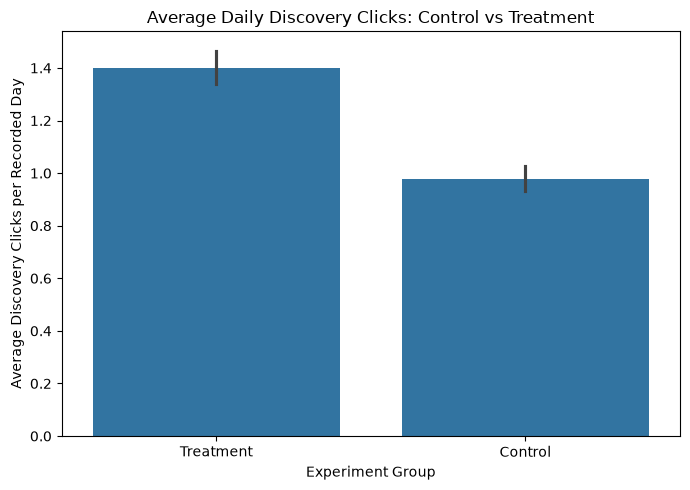

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.barplot(
    data=secondary_analysis,
    x='Variant',
    y='Daily_Discovery_Clicks',
    errorbar=('ci', 95)
)

plt.title('Average Daily Discovery Clicks: Control vs Treatment')
plt.xlabel('Experiment Group')
plt.ylabel('Average Discovery Clicks per Recorded Day')

plt.tight_layout()
plt.show()

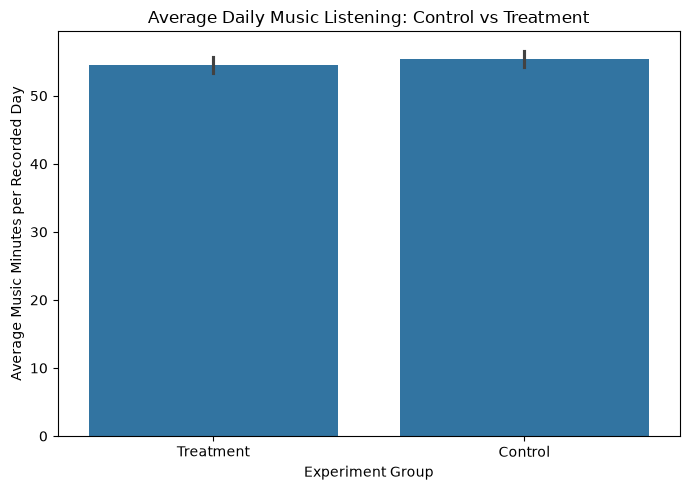

In [14]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=secondary_analysis,
    x='Variant',
    y='Daily_Music_Minutes',
    errorbar=('ci', 95)
)

plt.title('Average Daily Music Listening: Control vs Treatment')
plt.xlabel('Experiment Group')
plt.ylabel('Average Music Minutes per Recorded Day')

plt.tight_layout()
plt.show()

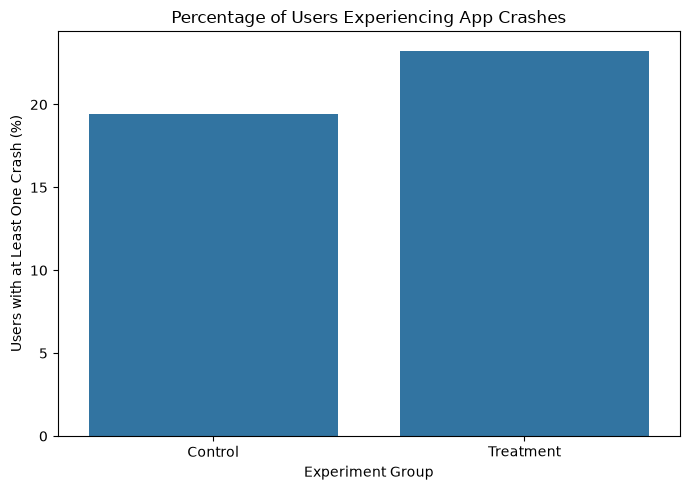

In [15]:
crash_percentages = (
    secondary_analysis.groupby('Variant')['Had_Crash']
    .mean()
    .reset_index()
)

crash_percentages['Crash_Percentage'] = (
    crash_percentages['Had_Crash'] * 100
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=crash_percentages,
    x='Variant',
    y='Crash_Percentage'
)

plt.title('Percentage of Users Experiencing App Crashes')
plt.xlabel('Experiment Group')
plt.ylabel('Users with at Least One Crash (%)')

plt.tight_layout()
plt.show()